# ДЗ 9.1 — Колебания стержня и цена диагональной массы

Однородный стержень $x\in[0,1]$, $\rho=E=1$, закреплённый с обоих концов:
$$u_{tt}=u_{xx},\qquad u(0,t)=u(1,t)=0,$$
$$u(x,0)=\sin(\pi x)+0.3\sin(5\pi x),\qquad u_t(x,0)=0 .$$
Точное решение:
$$u(x,t)=\sin(\pi x)\cos(\pi t)+0.3\,\sin(5\pi x)\cos(5\pi t).$$

## Метод

**Постановка.** $\rho(x)u_{tt}=\partial_x\big(E(x)u_x\big)$, $u(0,t)=u(1,t)=0$. Умножение на $w$
и интегрирование по частям дают
$$\int\rho\,u_{tt}w\,dx+\int E\,u_xw_x\,dx=0,$$
а при кусочно-линейной аппроксимации $u_h(x,t)=\sum_iU_i(t)\varphi_i(x)$ — систему $M\ddot U+KU=0$.

**Локальные матрицы** элемента длины $h_e$ с постоянными $\rho_e,E_e$:
$$M_e=\frac{\rho_eh_e}{6}\begin{pmatrix}2&1\\1&2\end{pmatrix},\qquad
K_e=\frac{E_e}{h_e}\begin{pmatrix}1&-1\\-1&1\end{pmatrix};$$
вклады соседних элементов в общий узел складываются. В этой задаче $\rho_e=E_e=1$, $h_e=h=1/N$.

**Диагональная масса.** $M_L=\operatorname{diag}(M\mathbf 1)$ — построчная сумма **полной** матрицы масс
(она же получается построчной суммой локальных $M_e$).
Порядок операций важен: сначала собираем массу и диагонализуем её на **полной** сетке, и только потом
исключаем закреплённые степени свободы. Суммирование строк уже сокращённой матрицы даст у узлов рядом
с закреплением $5h/6$ вместо $h$ — это показано в следующей ячейке.

**Скоростная форма Верле** (kick–drift–kick):
$$a^n=-M_*^{-1}KU^n,\qquad V^{n+1/2}=V^n+\frac{\Delta t}{2}a^n,\qquad
U^{n+1}=U^n+\Delta t\,V^{n+1/2},$$
$$a^{n+1}=-M_*^{-1}KU^{n+1},\qquad V^{n+1}=V^{n+1/2}+\frac{\Delta t}{2}a^{n+1},$$
где $M_*=M_L$ или $M$. Для согласованной массы $M^{-1}$ явно не строится: матрица постоянна, поэтому
её LU-разложение делается один раз, а на каждом шаге решается система. Для диагональной массы —
просто деление на диагональ. Начальные условия: $U^0$ — значения $u(x,0)$ в узлах, $V^0=0$.

**Энергия** считается по перемещениям и скоростям одного слоя:
$$H_n=\frac12\,V^{n\,\mathsf T}M_*V^n+\frac12\,U^{n\,\mathsf T}KU^n .$$
У системы ОДУ она сохраняется точно, а схема Верле — лишь приближённо (колебания $\mathcal{O}(\Delta t^2)$).
Для контроля считается и сдвинутый инвариант
$\frac12v^{n+1/2\,\mathsf T}M_*v^{n+1/2}+\frac12U^{n\,\mathsf T}KU^{n+1}$, который схема сохраняет точно.

## Инфраструктура

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sla
from matplotlib.animation import FuncAnimation, PillowWriter

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "figure.facecolor": "white",
})

os.makedirs("figs", exist_ok=True)


def exact_solution(x, t):
    """Точное решение задачи."""
    return (np.sin(np.pi * x) * np.cos(np.pi * t)
            + 0.3 * np.sin(5 * np.pi * x) * np.cos(5 * np.pi * t))


def initial_displacement(N):
    """Начальные перемещения во внутренних узлах."""
    x = np.linspace(0.0, 1.0, N + 1)
    return (np.sin(np.pi * x) + 0.3 * np.sin(5 * np.pi * x))[1:-1]


def make_grid(N):
    return np.linspace(0.0, 1.0, N + 1)


def full_profile(u_int):
    """Вектор внутренних узлов -> полный профиль с нулями на закреплённых концах."""
    return np.concatenate(([0.0], np.asarray(u_int, float), [0.0]))

## Сборка матриц из локальных матриц элементов

Цикл по элементам, как в методе конечных элементов. Масса диагонализуется построчным суммированием
**полной** матрицы, и только после этого накладываются закрепления.

In [2]:
def assemble(N, rho=1.0, E=1.0):
    """Сборка ПОЛНЫХ K и M (согласованной) из локальных матриц линейных элементов.

    K_e = (E/h)[[1,-1],[-1,1]],  M_e = (rho*h/6)[[2,1],[1,2]].
    """
    h = 1.0 / N
    Ke = E / h * np.array([[1.0, -1.0], [-1.0, 1.0]])
    Me = rho * h / 6.0 * np.array([[2.0, 1.0], [1.0, 2.0]])

    K_full = np.zeros((N + 1, N + 1))
    M_full = np.zeros((N + 1, N + 1))
    for e in range(N):
        loc = [e, e + 1]
        K_full[np.ix_(loc, loc)] += Ke
        M_full[np.ix_(loc, loc)] += Me
    return K_full, M_full, h


def lump(M_full):
    """Диагональная масса: M_L = diag(M * 1) -- построчная сумма полной матрицы."""
    return np.diag(M_full.sum(axis=1))


def free(A):
    """Исключение закреплённых степеней свободы (u = 0 на концах)."""
    return A[1:-1, 1:-1]


def matrices(N, mass="lumped"):
    """K и M на свободных узлах. Масса диагонализуется ДО исключения связей."""
    K_full, M_full, h = assemble(N)
    if mass == "lumped":
        M_full = lump(M_full)
    return free(K_full), free(M_full), h


N_ch = 8
K_full, M_full, h_ch = assemble(N_ch)
M_L_full = lump(M_full)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
print("M (согласованная, N=8):\n", M_full)
print("\nM_L = diag(M*1):\n", M_L_full)
print("\nK (внутренние узлы):\n", free(K_full))

ones = np.ones(N_ch + 1)
diag_L = np.diag(M_L_full)
tests = [
    ("K симметрична", np.allclose(K_full, K_full.T)),
    ("K * 1 = 0 (жёсткое смещение не создаёт усилий)", np.allclose(K_full @ ones, 0.0)),
    ("M * 1 = h внутри, h/2 на закреплённых концах",
     np.allclose((M_full @ ones)[1:-1], h_ch) and np.allclose((M_full @ ones)[[0, -1]], h_ch / 2)),
    ("M_L = diag(M*1): h внутри, h/2 на концах",
     np.allclose(diag_L[1:-1], h_ch) and np.allclose(diag_L[[0, -1]], h_ch / 2)),
    ("после исключения связей M_L = h*I", np.allclose(free(M_L_full), h_ch * np.eye(N_ch - 1))),
    ("M_L диагональна", np.allclose(M_L_full, np.diag(np.diag(M_L_full)))),
    ("M симметрична и положительно определена",
     np.allclose(M_full, M_full.T) and np.all(np.linalg.eigvalsh(M_full) > 0)),
    ("суммарная масса = rho*L = 1", np.isclose(M_L_full.sum(), 1.0)
     and np.isclose(M_full.sum(), 1.0)),
    ("в сокращённой системе N-1 неизвестных", free(K_full).shape == (N_ch - 1, N_ch - 1)),
]
print()
for name, ok in tests:
    print(("  [OK]   " if ok else "  [FAIL] ") + name)

M (согласованная, N=8):
 [[0.0417 0.0208 0.     0.     0.     0.     0.     0.     0.    ]
 [0.0208 0.0833 0.0208 0.     0.     0.     0.     0.     0.    ]
 [0.     0.0208 0.0833 0.0208 0.     0.     0.     0.     0.    ]
 [0.     0.     0.0208 0.0833 0.0208 0.     0.     0.     0.    ]
 [0.     0.     0.     0.0208 0.0833 0.0208 0.     0.     0.    ]
 [0.     0.     0.     0.     0.0208 0.0833 0.0208 0.     0.    ]
 [0.     0.     0.     0.     0.     0.0208 0.0833 0.0208 0.    ]
 [0.     0.     0.     0.     0.     0.     0.0208 0.0833 0.0208]
 [0.     0.     0.     0.     0.     0.     0.     0.0208 0.0417]]

M_L = diag(M*1):
 [[0.0625 0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.125  0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.125  0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.125  0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.125  0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0

In [3]:
# Ловушка из методички: сумма строк УЖЕ сокращённой матрицы даёт другие массы у закреплений
M_L_full = lump(M_full)
M_L_inside = np.diag(free(M_L_full))            # правильно: диагонализация до исключения связей
M_L_wrong = free(M_full).sum(axis=1)            # неправильно: построчная сумма сокращённой матрицы

print("масса первого внутреннего узла:")
print("  правильно (diag(M*1) на полной сетке): %.6f = h" % M_L_inside[0])
print("  неправильно (row-sum сокращённой)   : %.6f = 5h/6" % M_L_wrong[0])
print("\nвсе массы, правильные   :", np.round(M_L_inside, 6))
print("все массы, неправильные :", np.round(M_L_wrong, 6))
print("\nразница затрагивает только два узла у закреплений (остальные совпадают):",
      np.allclose(M_L_inside[1:-1], M_L_wrong[1:-1]))

масса первого внутреннего узла:
  правильно (diag(M*1) на полной сетке): 0.125000 = h
  неправильно (row-sum сокращённой)   : 0.104167 = 5h/6

все массы, правильные   : [0.125 0.125 0.125 0.125 0.125 0.125 0.125]
все массы, неправильные : [0.1042 0.125  0.125  0.125  0.125  0.125  0.1042]

разница затрагивает только два узла у закреплений (остальные совпадают): True


## Решатель: скоростная форма Верле и энергии

In [4]:
def verlet(N, mass, dt, T_final, u0_int=None, stop=1e12):
    """Скоростная форма Верле для M U'' + K U = 0.

    Возвращает (U, V, K, M): массивы слоёв (n_steps+1, N-1) для перемещений и скоростей.
    Счёт прекращается, если |U| > stop (защита от переполнения).
    """
    K, M, h = matrices(N, mass)
    U = initial_displacement(N) if u0_int is None else np.asarray(u0_int, float).copy()
    V = np.zeros_like(U)

    if mass == "lumped":
        inv_diag = 1.0 / np.diag(M)                 # диагональная масса: просто деление
        def acc(Uc):
            return -(inv_diag * (K @ Uc))
    else:
        lu = sla.lu_factor(M)                       # согласованная: LU один раз
        def acc(Uc):
            return -sla.lu_solve(lu, K @ Uc)

    nsteps = int(np.ceil(T_final / dt))
    Uh = np.empty((nsteps + 1, U.size))
    Vh = np.empty_like(Uh)
    Uh[0] = U
    Vh[0] = V
    a = acc(U)
    for n in range(nsteps):
        V_half = V + 0.5 * dt * a                   # kick
        U = U + dt * V_half                         # drift
        a = acc(U)
        V = V_half + 0.5 * dt * a                   # kick
        Uh[n + 1] = U
        Vh[n + 1] = V
        if np.abs(U).max() > stop:
            return Uh[:n + 2], Vh[:n + 2], K, M
    return Uh, Vh, K, M


def energy(K, M, U, V):
    """H_n = 1/2 V^T M V + 1/2 U^T K U -- по перемещениям и скоростям одного слоя."""
    return 0.5 * np.einsum("ij,ij->i", V, V @ M) + 0.5 * np.einsum("ij,ij->i", U, U @ K)


def energy_staggered(K, M, U, dt):
    """Сдвинутый инвариант Верле (сохраняется точно) -- только для контроля."""
    v = (U[1:] - U[:-1]) / dt
    return 0.5 * np.einsum("ij,ij->i", v, v @ M) + 0.5 * np.einsum("ij,ij->i", U[:-1], U[1:] @ K)


def rel(E):
    return (E - E[0]) / abs(E[0])

## Зелёный уровень: диагональная масса, $\Delta t=0.5h$

Сетки $N=40,80,160$, $\Delta t=0.5h$ (для диагональной массы это $0.5\,\Delta t_{crit}$, с большим запасом).
Сравнение с точным решением при $t=0.25,\;0.75,\;2.25$.

In [5]:
N_list = [40, 80, 160]
t_check = [0.25, 0.75, 2.25]
T_end = max(t_check)

err_lump = np.zeros((len(N_list), len(t_check)))
energy_lump = []

print("Диагональная масса M_L = diag(M*1), скоростная форма Верле, dt = 0.5h")
print("    N |     h    |    dt    |" + "".join("  e_inf(t=%.2f)" % T for T in t_check)
      + " |  max |dH|/H0")
print("-" * 92)
for i, N in enumerate(N_list):
    h = 1.0 / N
    dt = 0.5 * h
    U, V, K, M = verlet(N, "lumped", dt, T_end)
    x = make_grid(N)
    for j, T in enumerate(t_check):
        k_float = T / dt
        k = int(round(k_float))
        assert abs(k_float - k) < 1e-9, "момент наблюдения не попал на сетку"
        err_lump[i, j] = np.max(np.abs(U[k] - exact_solution(x[1:-1], k * dt)))
    H = energy(K, M, U, V)
    energy_lump.append(np.max(np.abs(rel(H))))
    print("  %3d | %8.5f | %8.5f |" % (N, h, dt)
          + "".join("  %.3e" % err_lump[i, j] for j in range(len(t_check)))
          + " |   %.2e" % energy_lump[-1])

print("\nВсе моменты наблюдения попадают на временную сетку (t/dt = %s для N=40)."
      % [round(T / (0.5 / 40), 3) for T in t_check])
print("\nНаблюдаемый порядок p = log2(e(N)/e(2N)):")
for j, T in enumerate(t_check):
    p = [np.log2(err_lump[i, j] / err_lump[i + 1, j]) for i in range(len(N_list) - 1)]
    print("  t=%.2f:  p = %.2f, %.2f" % (T, p[0], p[1]))

Диагональная масса M_L = diag(M*1), скоростная форма Верле, dt = 0.5h
    N |     h    |    dt    |  e_inf(t=0.25)  e_inf(t=0.75)  e_inf(t=2.25) |  max |dH|/H0
--------------------------------------------------------------------------------------------
   40 |  0.02500 |  0.01250 |  4.072e-03  1.267e-02  3.374e-02 |   6.67e-03
   80 |  0.01250 |  0.00625 |  1.024e-03  3.099e-03  9.038e-03 |   1.69e-03
  160 |  0.00625 |  0.00313 |  2.562e-04  7.704e-04  2.295e-03 |   4.24e-04

Все моменты наблюдения попадают на временную сетку (t/dt = [20.0, 60.0, 180.0] для N=40).

Наблюдаемый порядок p = log2(e(N)/e(2N)):
  t=0.25:  p = 1.99, 2.00
  t=0.75:  p = 2.03, 2.01
  t=2.25:  p = 1.90, 1.98


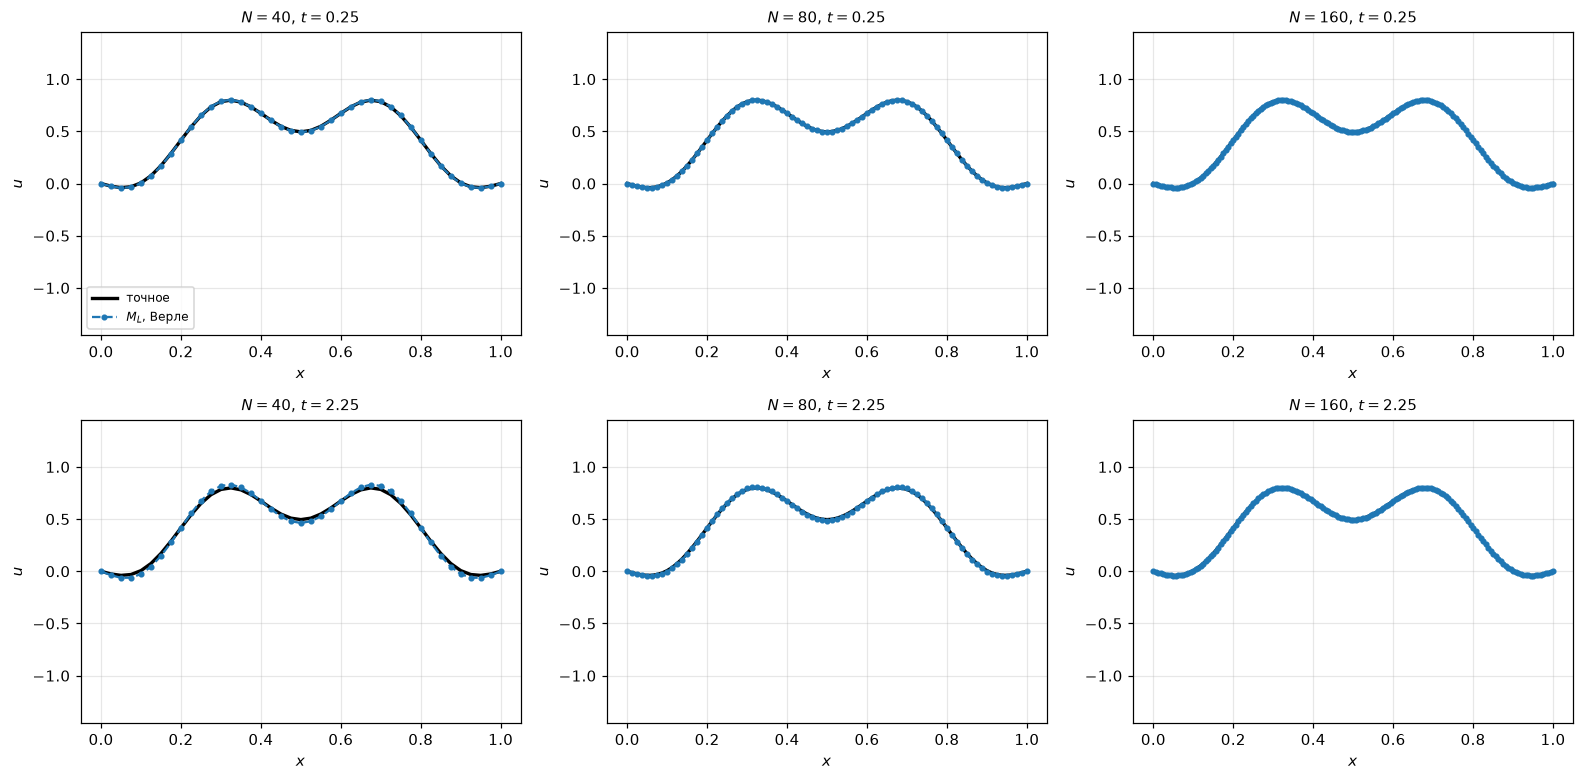

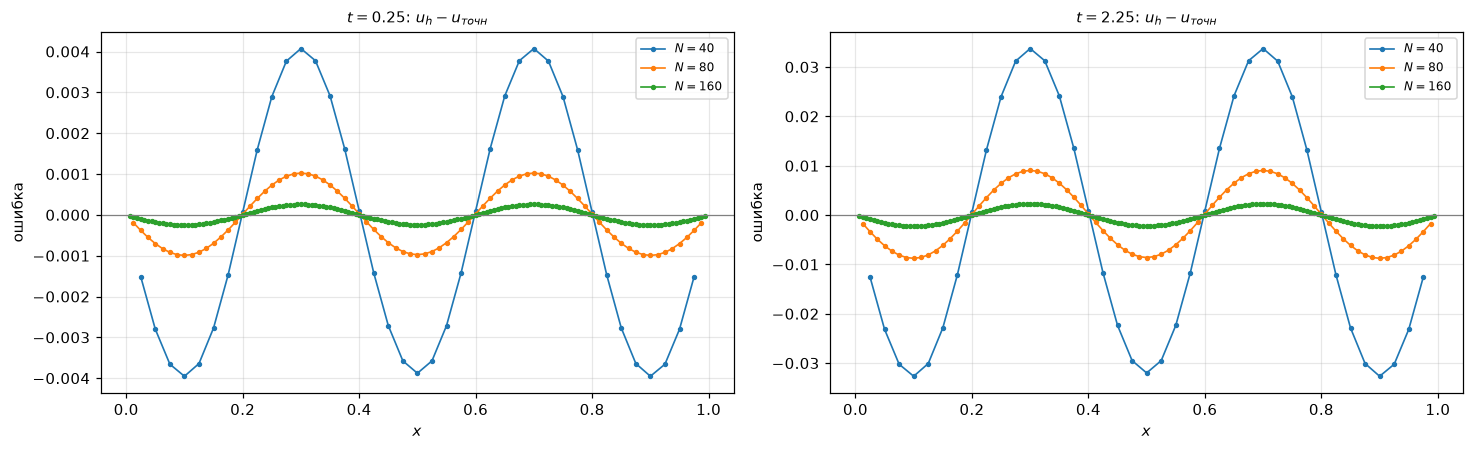

In [6]:
fig, axes = plt.subplots(2, len(N_list), figsize=(14.5, 7.2))
for row, T in enumerate((0.25, 2.25)):
    for col, N in enumerate(N_list):
        h = 1.0 / N
        dt = 0.5 * h
        U, V, K, M = verlet(N, "lumped", dt, T)
        x = make_grid(N)
        k = int(round(T / dt))
        ax = axes[row, col]
        ax.plot(x, exact_solution(x, k * dt), "k-", lw=2.2, label="точное")
        ax.plot(x, full_profile(U[k]), "o--", ms=3, color="tab:blue", label="$M_L$, Верле")
        ax.set_title("$N=%d$, $t=%g$" % (N, T))
        ax.set_xlabel("$x$")
        ax.set_ylabel("$u$")
        ax.set_ylim(-1.45, 1.45)
        if row == 0 and col == 0:
            ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

# Где именно сидит ошибка: разность численного и точного решений
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
for ax, T in zip(axes, (0.25, 2.25)):
    for N in N_list:
        h = 1.0 / N
        dt = 0.5 * h
        U, V, K, M = verlet(N, "lumped", dt, T)
        x = make_grid(N)
        k = int(round(T / dt))
        ax.plot(x[1:-1], U[k] - exact_solution(x[1:-1], k * dt), "o-", ms=2.5, lw=1.1,
                label="$N=%d$" % N)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title("$t=%g$: $u_h-u_{точн}$" % T)
    ax.set_xlabel("$x$")
    ax.set_ylabel("ошибка")
    ax.legend()
plt.tight_layout()
plt.show()

Профили при $t=0.25$ практически совпадают с точными, а к $t=2.25$ видно отставание по фазе
(особенно в районе второго узла пучности) — при том, что энергия сохраняется идеально.

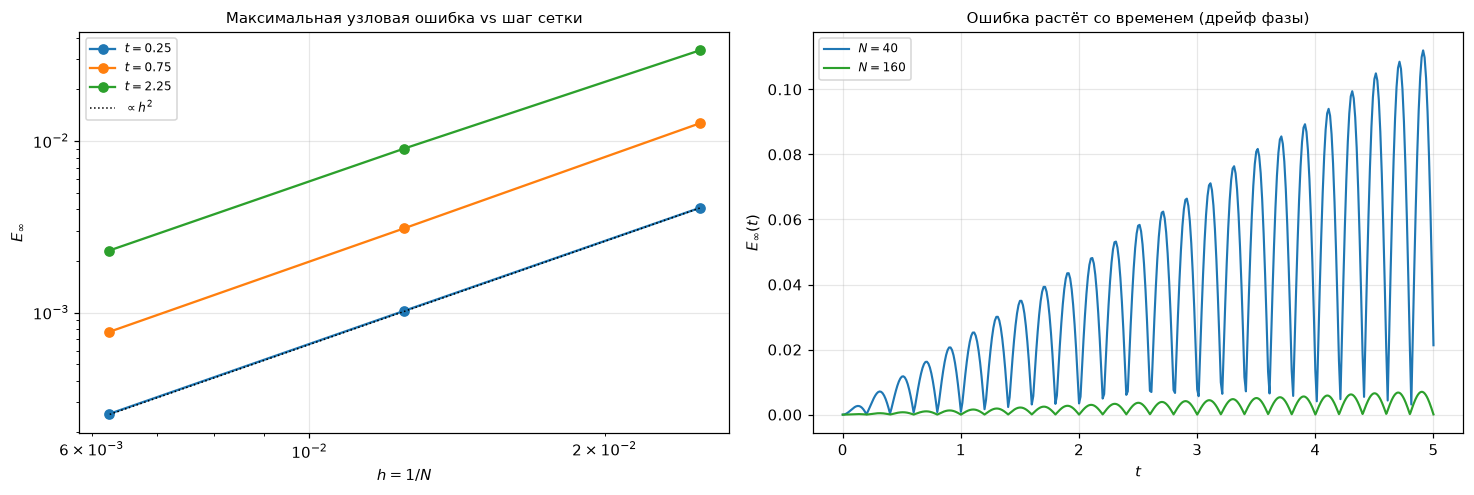

Максимум по t на [0,5]: N=40 -> 1.12e-01, N=160 -> 7.01e-03 (отношение 16.0; при втором порядке ждём 16)


In [7]:
# Ошибка как функция времени и как функция шага
N_long = 40
h_long = 1.0 / N_long
dt_long = 0.5 * h_long
U_l, V_l, K_l, M_l = verlet(N_long, "lumped", dt_long, 5.0)
x_l = make_grid(N_long)[1:-1]
ts = np.arange(len(U_l)) * dt_long
e_t40 = np.array([np.max(np.abs(U_l[k] - exact_solution(x_l, ts[k]))) for k in range(len(U_l))])

N_long2 = 160
h2 = 1.0 / N_long2
dt2 = 0.5 * h2
U_l2, _, _, _ = verlet(N_long2, "lumped", dt2, 5.0)
x_l2 = make_grid(N_long2)[1:-1]
ts2 = np.arange(len(U_l2)) * dt2
e_t160 = np.array([np.max(np.abs(U_l2[k] - exact_solution(x_l2, ts2[k]))) for k in range(len(U_l2))])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
hs = np.array([1.0 / N for N in N_list])
for j, T in enumerate(t_check):
    ax.loglog(hs, err_lump[:, j], "o-", label="$t=%g$" % T)
ax.loglog(hs, 6.5 * hs ** 2, "k:", lw=1.0, label="$\\propto h^2$")
ax.set_xlabel("$h=1/N$")
ax.set_ylabel("$E_\\infty$")
ax.set_title("Максимальная узловая ошибка vs шаг сетки")
ax.legend()

ax = axes[1]
ax.plot(ts, e_t40, color="tab:blue", lw=1.4, label="$N=40$")
ax.plot(ts2, e_t160, color="tab:green", lw=1.4, label="$N=160$")
ax.set_xlabel("$t$")
ax.set_ylabel("$E_\\infty(t)$")
ax.set_title("Ошибка растёт со временем (дрейф фазы)")
ax.legend()
plt.tight_layout()
plt.show()

print("Максимум по t на [0,5]: N=40 -> %.2e, N=160 -> %.2e (отношение %.1f; при втором порядке ждём 16)"
      % (e_t40.max(), e_t160.max(), e_t40.max() / e_t160.max()))

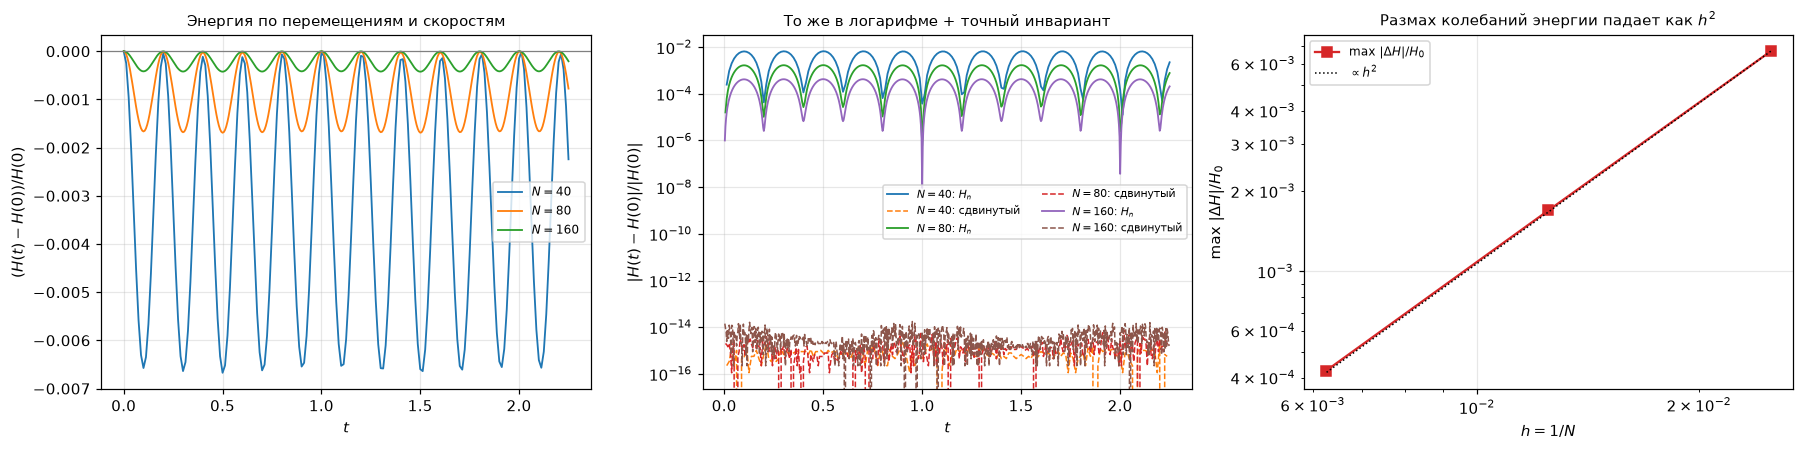

  N= 40: max |dH|/H0 = 6.67e-03
  N= 80: max |dH|/H0 = 1.69e-03
  N=160: max |dH|/H0 = 4.24e-04


In [8]:
# Энергия H_n по методичке (один слой: перемещения и скорости) + контроль сдвинутым инвариантом
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2))

ax = axes[0]
for N in N_list:
    h = 1.0 / N
    dt = 0.5 * h
    U, V, K, M = verlet(N, "lumped", dt, T_end)
    H = energy(K, M, U, V)
    t = np.arange(len(H)) * dt
    ax.plot(t, rel(H), lw=1.2, label="$N=%d$" % N)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("$t$")
ax.set_ylabel("$(H(t)-H(0))/H(0)$")
ax.set_title("Энергия по перемещениям и скоростям")
ax.legend()

ax = axes[1]
for N in N_list:
    h = 1.0 / N
    dt = 0.5 * h
    U, V, K, M = verlet(N, "lumped", dt, T_end)
    H = energy(K, M, U, V)
    Hs = energy_staggered(K, M, U, dt)
    t = np.arange(len(H)) * dt
    ax.semilogy(t[1:], np.abs(rel(H))[1:], lw=1.2, label="$N=%d$: $H_n$" % N)
    ax.semilogy(t[:-1][1:], np.abs(rel(Hs))[1:], "--", lw=1.0, label="$N=%d$: сдвинутый" % N)
ax.set_xlabel("$t$")
ax.set_ylabel("$|H(t)-H(0)|/|H(0)|$")
ax.set_title("То же в логарифме + точный инвариант")
ax.legend(fontsize=7, ncol=2)

ax = axes[2]
depth = []
for N in N_list:
    h = 1.0 / N
    dt = 0.5 * h
    U, V, K, M = verlet(N, "lumped", dt, T_end)
    depth.append(np.max(np.abs(rel(energy(K, M, U, V)))))
ax.loglog(hs, depth, "s-", color="tab:red", label="max $|\\Delta H|/H_0$")
ax.loglog(hs, depth[0] * (hs / hs[0]) ** 2, "k:", lw=1.0, label="$\\propto h^2$")
ax.set_xlabel("$h=1/N$")
ax.set_ylabel("max $|\\Delta H|/H_0$")
ax.set_title("Размах колебаний энергии падает как $h^2$")
ax.legend()
plt.tight_layout()
plt.show()

for N, d in zip(N_list, depth):
    print("  N=%3d: max |dH|/H0 = %.2e" % (N, d))

### Анимация колебаний

Численное решение (точки) наложено на точное (штриховая линия); снизу — текущая ошибка.

анимация сохранена: figs/wave_oscillations.gif  (кадров: 54)


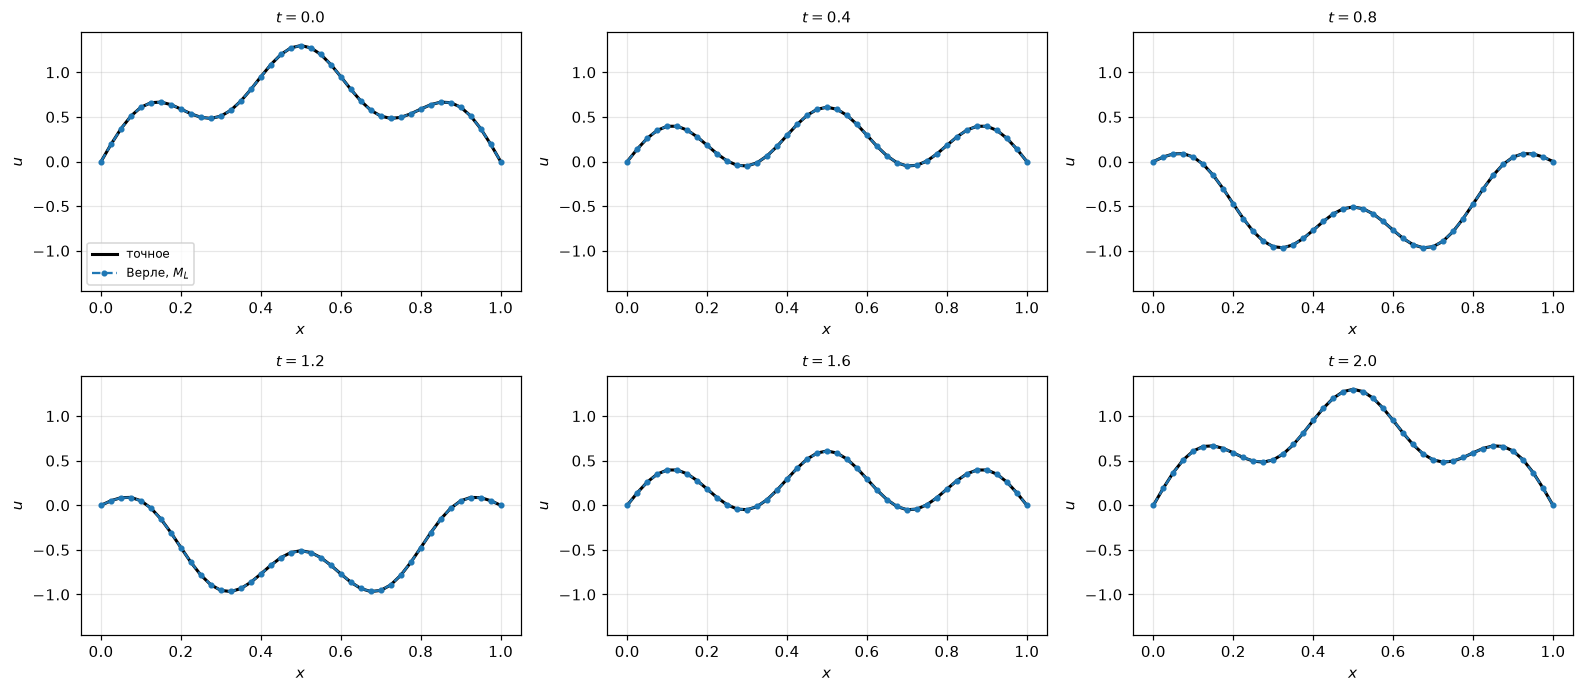

In [9]:
N_anim = 40
h_a = 1.0 / N_anim
dt_a = 0.5 * h_a
U_a, V_a, K_a, M_a = verlet(N_anim, "lumped", dt_a, 2.0)
x_a = make_grid(N_anim)
t_a = np.arange(len(U_a)) * dt_a
frames = list(range(0, len(U_a), 3))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.8, 4.6), sharex=True,
                               gridspec_kw=dict(height_ratios=[2.4, 1.0]))
ax1.set_xlim(0, 1)
ax1.set_ylim(-1.45, 1.45)
ax1.set_ylabel("$u$")
ax1.set_title("Колебания стержня: $N=40$, $\\Delta t=0.5h$, диагональная масса")
ax2.set_xlim(0, 1)
ax2.set_ylim(-0.12, 0.06)
ax2.set_xlabel("$x$")
ax2.set_ylabel("ошибка")

line_num, = ax1.plot([], [], "o-", ms=3.5, lw=1.2, color="tab:blue", label="численное")
line_ex, = ax1.plot([], [], "k--", lw=1.6, label="точное")
line_err, = ax2.plot([], [], "-", lw=1.2, color="tab:red")
text_t = ax1.text(0.02, 0.94, "", transform=ax1.transAxes, fontsize=10)
ax1.legend(loc="lower left", ncol=2)


def init():
    line_num.set_data([], [])
    line_ex.set_data([], [])
    line_err.set_data([], [])
    text_t.set_text("")
    return line_num, line_ex, line_err, text_t


def update(k):
    u = full_profile(U_a[k])
    t = t_a[k]
    line_num.set_data(x_a, u)
    line_ex.set_data(x_a, exact_solution(x_a, t))
    line_err.set_data(x_a[1:-1], u[1:-1] - exact_solution(x_a[1:-1], t))
    text_t.set_text("$t=%.3f$" % t)
    return line_num, line_ex, line_err, text_t


anim = FuncAnimation(fig, update, frames=frames, init_func=init, interval=40, blit=False)
anim.save("figs/wave_oscillations.gif", writer=PillowWriter(fps=20), dpi=90)
plt.close(fig)
print("анимация сохранена: figs/wave_oscillations.gif  (кадров: %d)" % len(frames))

# Статичная «раскадровка» — тот же расчёт, шесть моментов времени
snap_t = [0.0, 0.4, 0.8, 1.2, 1.6, 2.0]
fig, axes = plt.subplots(2, 3, figsize=(14.5, 6.4))
for ax, T in zip(axes.ravel(), snap_t):
    k = int(round(T / dt_a))
    ax.plot(x_a, exact_solution(x_a, k * dt_a), "k-", lw=2.0, label="точное")
    ax.plot(x_a, full_profile(U_a[k]), "o--", ms=3, color="tab:blue", label="Верле, $M_L$")
    ax.set_title("$t=%.1f$" % (k * dt_a))
    ax.set_xlabel("$x$")
    ax.set_ylabel("$u$")
    ax.set_ylim(-1.45, 1.45)
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

![Колебания стержня: численное решение и точное](figs/wave_oscillations.gif)

### Откуда берётся ошибка при идеальной энергии

Дискретное решение — ровно две моды с частотами Верле $\tilde\omega_j$, поэтому ошибка — это
целиком фазовый сдвиг. Проверим это численно и посчитаем сдвиги.

In [10]:
N_ph = 40
h_ph = 1.0 / N_ph
dt_ph = 0.5 * h_ph
K_ph, M_ph, _ = matrices(N_ph, "lumped")
w2_ph = sla.eigh(K_ph, M_ph, eigvals_only=True)
w_ph = np.sqrt(w2_ph)
wv_ph = 2.0 / dt_ph * np.arcsin(w_ph * dt_ph / 2.0)

U_ph, V_ph, K_ph, M_ph = verlet(N_ph, "lumped", dt_ph, 2.25)
x_ph = make_grid(N_ph)[1:-1]
t_ph = np.arange(len(U_ph)) * dt_ph

model = np.array([
    np.sin(np.pi * x_ph) * np.cos(wv_ph[0] * t) + 0.3 * np.sin(5 * np.pi * x_ph) * np.cos(wv_ph[4] * t)
    for t in t_ph])

print("Отличие численного решения от двухмодовой модели: %.2e  (это округление)"
      % np.max(np.abs(U_ph - model)))
print()
print("Частоты при N=40, dt=0.5h:")
for j in (1, 5):
    print("  мода %d: точная %.6f | w_h %.6f (отн. %+.2e) | w~Верле %.6f (отн. %+.2e)"
          % (j, j * np.pi, w_ph[j - 1], w_ph[j - 1] / (j * np.pi) - 1,
             wv_ph[j - 1], wv_ph[j - 1] / (j * np.pi) - 1))
print()
print("   t     E_inf(набл.)   фазовый сдвиг моды 5   |cos(5pi t) - cos(w~t)|*0.3")
for T in t_check:
    k = int(round(T / dt_ph))
    shift = (wv_ph[4] - 5 * np.pi) * t_ph[k]
    print("  %.2f    %.3e      %+.4f рад (%+.1f град)      %.3e"
          % (T, np.max(np.abs(U_ph[k] - exact_solution(x_ph, t_ph[k]))),
             shift, np.degrees(shift),
             0.3 * abs(np.cos(5 * np.pi * t_ph[k]) - np.cos(wv_ph[4] * t_ph[k]))))

Отличие численного решения от двухмодовой модели: 4.14e-14  (это округление)

Частоты при N=40, dt=0.5h:
  мода 1: точная 3.141593 | w_h 3.140785 (отн. -2.57e-04) | w~Верле 3.140987 (отн. -1.93e-04)
  мода 5: точная 15.707963 | w_h 15.607226 (отн. -6.41e-03) | w~Верле 15.632083 (отн. -4.83e-03)

   t     E_inf(набл.)   фазовый сдвиг моды 5   |cos(5pi t) - cos(w~t)|*0.3
  0.25    4.072e-03      -0.0190 рад (-1.1 град)      3.986e-03
  0.75    1.267e-02      -0.0569 рад (-3.3 град)      1.241e-02
  2.25    3.374e-02      -0.1707 рад (-9.8 град)      3.296e-02


## Вывод по зелёному уровню

**Нет, идеальное сохранение энергии не означает правильную фазу.**

* Энергия $H_n=\tfrac12V^{n\mathsf T}M_LV^n+\tfrac12U^{n\mathsf T}KU^n$ колеблется в узкой полосе
  под $H_0$: $0\ldots-0.67\%$ при $N=40$, $0\ldots-0.04\%$ при $N=160$; размах падает ровно как $h^2$
  ($6.7\cdot10^{-3}\to1.7\cdot10^{-3}\to4.2\cdot10^{-4}$) и **не растёт со временем** — на $[0,20]$
  амплитуда та же. Сдвинутый инвариант $\tfrac12v^{n+1/2\mathsf T}M_Lv^{n+1/2}+\tfrac12U^{n\mathsf T}KU^{n+1}$
  сохраняется на уровне машинной точности ($10^{-15}$), то есть схема не «теряет» энергию вовсе.
* Ошибка профиля при этом **растёт линейно по времени**: $E_\infty=4.1\cdot10^{-3}$ при $t=0.25$,
  $1.3\cdot10^{-2}$ при $t=0.75$, $3.4\cdot10^{-2}$ при $t=2.25$ (сетка $N=40$). Причина — не затухание,
  а накопление фазового сдвига $\Delta\varphi_j=(\tilde\omega_j-\omega_j)\,t$: у моды 5 при $N=40$ это
  $-1.1^{\circ}$ к $t=0.25$, $-9.8^{\circ}$ к $t=2.25$ и около $-43^{\circ}$ к $t=10$. Наблюдаемая ошибка
  совпадает с $0.3\,|\cos5\pi t-\cos\tilde\omega_5t|$ — то есть это ровно фаза второй моды.
* Энергия — интеграл движения, она нечувствительна к сдвигу фазы: амплитуды мод те же, поэтому
  $H_n$ и «не замечает» ошибку. Более того, ошибка второго порядка по $h$ при фиксированном $t$
  и линейный рост по $t$ означают, что на больших временах любая схема «разъедется» по фазе.
* Диагональная масса систематически **занижает** частоты (отставание по фазе), схема Верле —
  наоборот, завышает; при $\Delta t\approx0.5\text{–}0.9h$ эти две ошибки частично компенсируются
  (см. жёлтый уровень).

## Жёлтый уровень: согласованная масса, собственные частоты, предельный шаг

Обобщённая задача $Kz=\omega_h^2Mz$ для обеих масс; сравнение с точными $\omega_j=j\pi$;
$\Delta t_{crit}=2/\omega_{h,\max}$.

In [11]:
N_freq = 80
h_f = 1.0 / N_freq
spec = {}
for mass in ("lumped", "consistent"):
    K, M, h = matrices(N_freq, mass)
    w2, Z = sla.eigh(K, M)
    spec[mass] = dict(w=np.sqrt(np.maximum(w2, 0.0)), Z=Z, K=K, M=M,
                      dt_crit=2.0 / np.sqrt(w2[-1]))

print("Собственные частоты, N=80 (h=%.5f)" % h_f)
print("   j  |  w_j = j*pi  |  M_L: w_h     отн. ошибка |  M: w_h       отн. ошибка")
print("-" * 88)
for j in (1, 2, 3, 5, 10, 20, 40, N_freq - 1):
    wl = spec["lumped"]["w"][j - 1]
    wc = spec["consistent"]["w"][j - 1]
    print("  %2d  |  %8.4f    |  %8.4f   %+10.2e   |  %8.4f   %+10.2e"
          % (j, j * np.pi, wl, wl / (j * np.pi) - 1, wc, wc / (j * np.pi) - 1))
print()
print("Предельный шаг Верле (dt_crit = 2/w_max):")
for mass, name in (("lumped", "M_L диагональная"), ("consistent", "M согласованная")):
    print("  %-16s w_max = %9.4f   dt_crit = %.6f   (h = %.6f, h/sqrt(3) = %.6f)"
          % (name, spec[mass]["w"][-1], spec[mass]["dt_crit"], h_f, h_f / np.sqrt(3)))
print("  отношение dt_crit: M_L / M = %.4f (теоретически sqrt(3) = 1.7321)"
      % (spec["lumped"]["dt_crit"] / spec["consistent"]["dt_crit"]))

Собственные частоты, N=80 (h=0.01250)
   j  |  w_j = j*pi  |  M_L: w_h     отн. ошибка |  M: w_h       отн. ошибка
----------------------------------------------------------------------------------------
   1  |    3.1416    |    3.1414    -6.43e-05   |    3.1418    +6.43e-05
   2  |    6.2832    |    6.2816    -2.57e-04   |    6.2848    +2.57e-04
   3  |    9.4248    |    9.4193    -5.78e-04   |    9.4302    +5.78e-04
   5  |   15.7080    |   15.6827    -1.61e-03   |   15.7332    +1.61e-03
  10  |   31.4159    |   31.2145    -6.41e-03   |   31.6182    +6.44e-03
  20  |   62.8319    |   61.2293    -2.55e-02   |   64.4566    +2.59e-02
  40  |  125.6637    |  113.1371    -9.97e-02   |  138.5641    +1.03e-01
  79  |  248.1858    |  159.9692    -3.55e-01   |  276.9680    +1.16e-01

Предельный шаг Верле (dt_crit = 2/w_max):
  M_L диагональная w_max =  159.9692   dt_crit = 0.012502   (h = 0.012500, h/sqrt(3) = 0.007217)
  M согласованная  w_max =  276.9680   dt_crit = 0.007221   (h = 0.01250

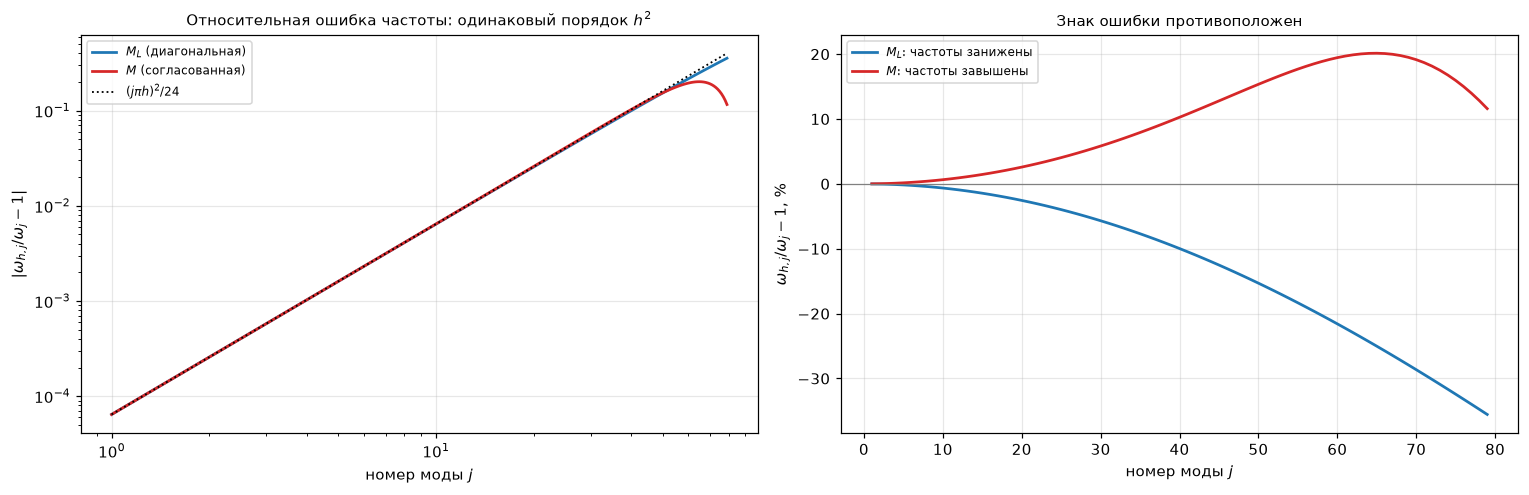

На малых j: M_L: -6.43e-05, M: +6.43e-05 (модули почти равны, знаки разные)
На верхней моде (j=79): M_L: -35.5%, M: +11.6%


In [12]:
j_all = np.arange(1, N_freq)
x_all = j_all * np.pi * h_f
rel_L = spec["lumped"]["w"] / (j_all * np.pi) - 1.0
rel_M = spec["consistent"]["w"] / (j_all * np.pi) - 1.0

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))

ax = axes[0]
ax.loglog(j_all, np.abs(rel_L), "-", color="tab:blue", lw=1.8, label="$M_L$ (диагональная)")
ax.loglog(j_all, np.abs(rel_M), "-", color="tab:red", lw=1.8, label="$M$ (согласованная)")
ax.loglog(j_all, x_all ** 2 / 24, "k:", lw=1.2, label="$(j\\pi h)^2/24$")
ax.set_xlabel("номер моды $j$")
ax.set_ylabel("$|\\omega_{h,j}/\\omega_j-1|$")
ax.set_title("Относительная ошибка частоты: одинаковый порядок $h^2$")
ax.legend()

ax = axes[1]
ax.plot(j_all, rel_L * 100, "-", color="tab:blue", lw=1.8, label="$M_L$: частоты занижены")
ax.plot(j_all, rel_M * 100, "-", color="tab:red", lw=1.8, label="$M$: частоты завышены")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("номер моды $j$")
ax.set_ylabel("$\\omega_{h,j}/\\omega_j-1$, %")
ax.set_title("Знак ошибки противоположен")
ax.legend()
plt.tight_layout()
plt.show()

print("На малых j: M_L: %+.2e, M: %+.2e (модули почти равны, знаки разные)"
      % (rel_L[0], rel_M[0]))
print("На верхней моде (j=%d): M_L: %+.1f%%, M: %+.1f%%"
      % (N_freq - 1, rel_L[-1] * 100, rel_M[-1] * 100))

### Сигнал $u(0.5,t)$ и энергия при одинаковом устойчивом шаге

Рабочий шаг $\Delta t=0.5h$ строго меньше $\Delta t_{crit}$ для **обеих** масс
($0.5h=0.87\,\Delta t_{crit}$ для согласованной). Затем шаг уменьшается вдвое при той же сетке.

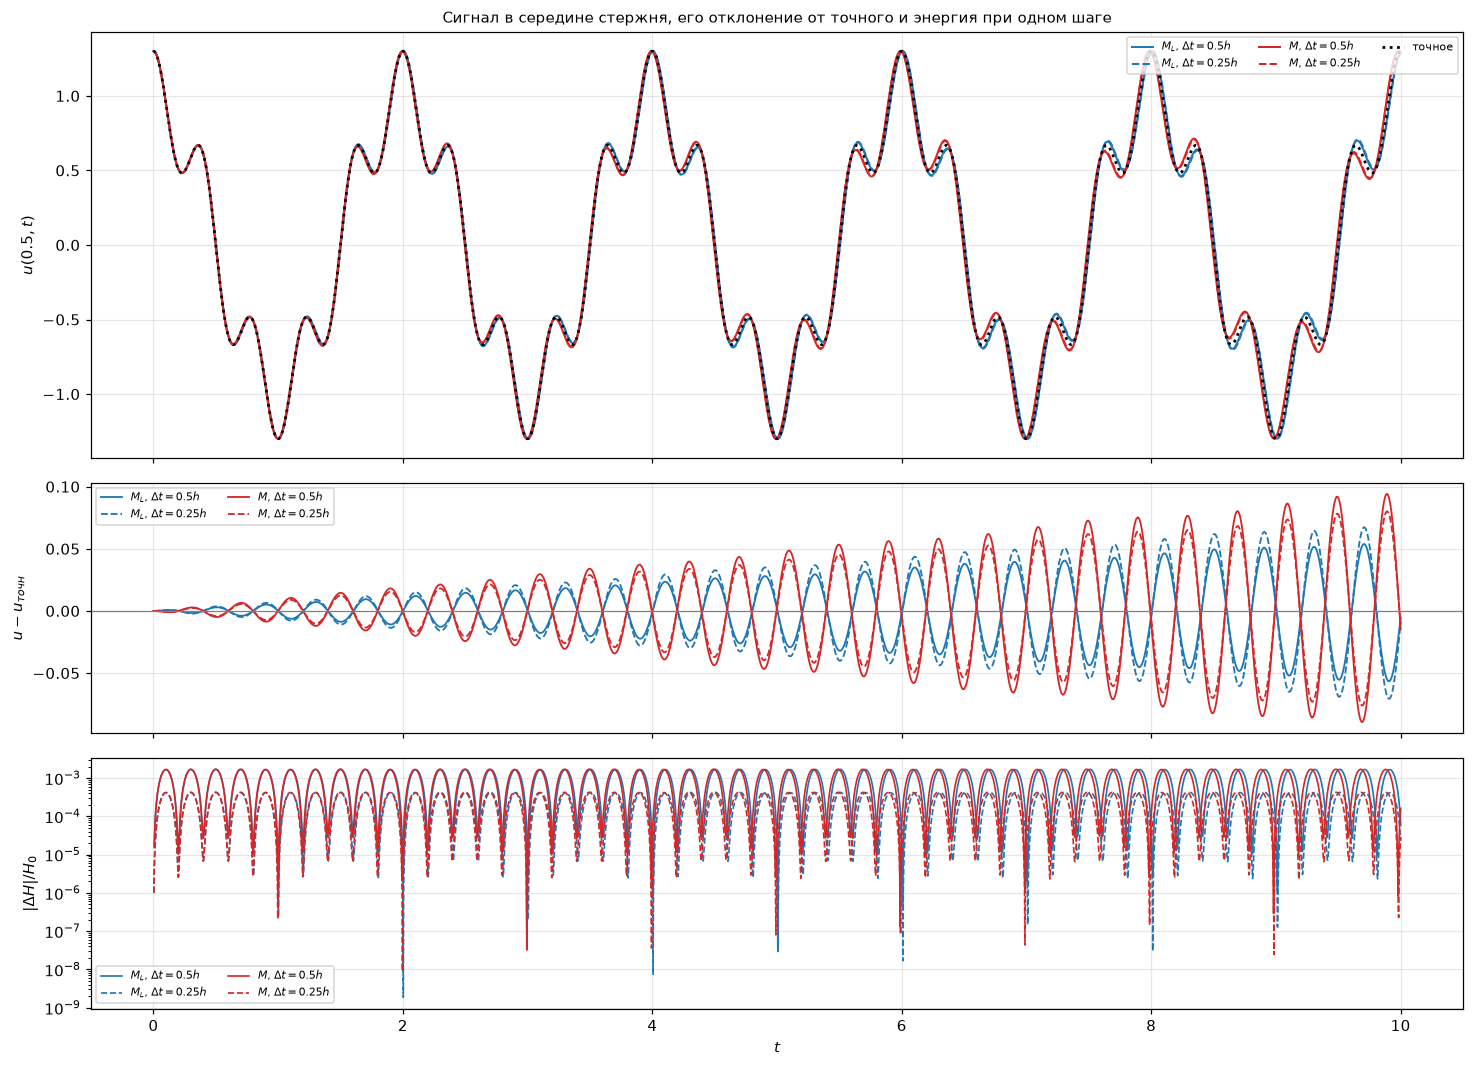

Максимальное отклонение сигнала u(0.5,t) от точного на [0, 10]:
  lumped     dt=0.5h: 5.663e-02
  lumped     dt=0.25h: 7.066e-02
  consistent dt=0.5h: 9.411e-02
  consistent dt=0.25h: 8.008e-02


In [13]:
N_y = 80
h_y = 1.0 / N_y
x_y = make_grid(N_y)
i_mid = N_y // 2 - 1                      # узел x = 0.5
T_sig = 10.0
step_txt = {1: "0.5h", 2: "0.25h"}
step_tex = {1: "$\\Delta t=0.5h$", 2: "$\\Delta t=0.25h$"}

fig, axes = plt.subplots(3, 1, figsize=(13.5, 9.8), sharex=True,
                         gridspec_kw=dict(height_ratios=[1.7, 1.0, 1.0]))
signals = {}
for mass, col, name in (("lumped", "tab:blue", "$M_L$"), ("consistent", "tab:red", "$M$")):
    for k in (1, 2):
        dt = 0.5 * h_y / k
        U, V, K, M = verlet(N_y, mass, dt, T_sig)
        t = np.arange(len(U)) * dt
        u = U[:, i_mid]
        ex = np.cos(np.pi * t) + 0.3 * np.cos(5 * np.pi * t)
        signals[(mass, k)] = (t, u, ex, dt)
        H = energy(K, M, U, V)
        ls = "-" if k == 1 else "--"
        lab = "%s, %s" % (name, step_tex[k])
        axes[0].plot(t, u, ls, color=col, lw=1.3, label=lab)
        axes[1].plot(t, u - ex, ls, color=col, lw=1.2, label=lab)
        axes[2].semilogy(t[1:], np.abs(rel(H))[1:], ls, color=col, lw=1.1, label=lab)

t_ex = np.linspace(0, T_sig, 4000)
axes[0].plot(t_ex, np.cos(np.pi * t_ex) + 0.3 * np.cos(5 * np.pi * t_ex), "k:", lw=1.8,
             label="точное")
axes[0].set_ylabel("$u(0.5,t)$")
axes[0].set_title("Сигнал в середине стержня, его отклонение от точного и энергия при одном шаге")
axes[0].legend(fontsize=7, ncol=3, loc="upper right")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_ylabel("$u-u_{точн}$")
axes[1].legend(fontsize=7, ncol=2)
axes[2].set_xlabel("$t$")
axes[2].set_ylabel("$|\\Delta H|/H_0$")
axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print("Максимальное отклонение сигнала u(0.5,t) от точного на [0, %.0f]:" % T_sig)
for (mass, k), (t, u, ex, dt) in signals.items():
    print("  %-10s dt=%s: %.3e" % (mass, step_txt[k], np.max(np.abs(u - ex))))

In [14]:
# Таблица e_inf для обеих масс: рабочий шаг и вдвое меньший
xe = make_grid(N_y)[1:-1]
print("Сетка N=80, ошибка E_inf при разных шагах по времени")
print("   масса       dt        t=2.25      t=10.0    max по t на [0,10]")
print("-" * 68)
rows = {}
for mass in ("lumped", "consistent"):
    for k in (1, 2):
        dt = 0.5 * h_y / k
        out = []
        for T in (2.25, 10.0):
            U, V, K, M = verlet(N_y, mass, dt, T)
            out.append(np.max(np.abs(U[-1] - exact_solution(xe, T))))
        U, V, K, M = verlet(N_y, mass, dt, 10.0)
        emax = max(np.max(np.abs(U[i] - exact_solution(xe, i * dt)))
                   for i in range(1, len(U)))
        rows[(mass, k)] = (out[0], out[1], emax)
        print("  %-10s  0.5h/%d   %.3e   %.3e   %.3e"
              % (mass, k, out[0], out[1], emax))

print()
print("То же при одинаковом запасе устойчивости dt = 0.9*dt_crit:")
for mass in ("lumped", "consistent"):
    dtc = spec[mass]["dt_crit"]
    dt = 0.9 * dtc
    U, V, K, M = verlet(N_y, mass, dt, 10.0)
    emax = max(np.max(np.abs(U[i] - exact_solution(xe, i * dt)))
               for i in range(1, len(U)))
    rows[(mass, "dtc")] = (np.max(np.abs(U[-1] - exact_solution(xe, 10.0))), None, emax)
    print("  %-10s dt=%.5f (0.9 dt_crit): max_t E_inf = %.3e" % (mass, dt, emax))

Сетка N=80, ошибка E_inf при разных шагах по времени
   масса       dt        t=2.25      t=10.0    max по t на [0,10]
--------------------------------------------------------------------
  lumped      0.5h/1   9.038e-03   5.364e-03   5.663e-02
  lumped      0.5h/2   1.123e-02   8.353e-03   7.066e-02
  consistent  0.5h/1   1.593e-02   1.485e-02   9.411e-02
  consistent  0.5h/2   1.346e-02   1.074e-02   8.008e-02

То же при одинаковом запасе устойчивости dt = 0.9*dt_crit:
  lumped     dt=0.01125 (0.9 dt_crit): max_t E_inf = 1.438e-02
  consistent dt=0.00650 (0.9 dt_crit): max_t E_inf = 9.569e-02


## Предельный шаг: 0.9, 1.00 и 1.05 от $\Delta t_{crit}$

Возмущение — верхняя мода: $u^0\to u^0+10^{-8}z_{\max}$, $\max_j|z_{\max,j}|=1$.
Счёт прекращается при $|u|>10^{10}$, чтобы не было переполнения.

In [15]:
N_st = 80
h_st = 1.0 / N_st
results = {}

print("Поведение возмущения верхней моды (10^-8), время счёта 2.0:")
print("   масса       множитель  dt         шагов  amp(t=0)   amp(конец)   max|u|")
print("-" * 88)
for mass in ("lumped", "consistent"):
    Z = spec[mass]["Z"]
    zmax = Z[:, -1] / np.abs(Z[:, -1]).max()
    M = spec[mass]["M"]
    dtc = spec[mass]["dt_crit"]
    u0 = initial_displacement(N_st) + 1e-8 * zmax
    for fac in (0.9, 1.0, 1.05):
        dt = fac * dtc
        U, V, K, M2 = verlet(N_st, mass, dt, 2.0, u0_int=u0, stop=1e10)
        amp = np.array([abs(zmax @ (M @ uu)) / (zmax @ (M @ zmax)) for uu in U])
        results[(mass, fac)] = (dt, U, amp)
        print("  %-11s %5.2f     %.5f   %5d   %.1e    %.2e     %.2e"
              % (mass, fac, dt, len(U) - 1, amp[0], amp[-1], np.abs(U[-1]).max()))

Поведение возмущения верхней моды (10^-8), время счёта 2.0:
   масса       множитель  dt         шагов  amp(t=0)   amp(конец)   max|u|
----------------------------------------------------------------------------------------
  lumped       0.90     0.01125     178   1.0e-08    9.41e-09     1.30e+00
  lumped       1.00     0.01250     160   1.0e-08    1.00e-08     1.30e+00
  lumped       1.05     0.01313      67   1.0e-08    1.06e+10     1.06e+10
  consistent   0.90     0.00650     308   1.0e-08    1.97e-09     1.30e+00
  consistent   1.00     0.00722     277   1.0e-08    1.00e-08     1.30e+00
  consistent   1.05     0.00758      67   1.0e-08    1.06e+10     1.06e+10


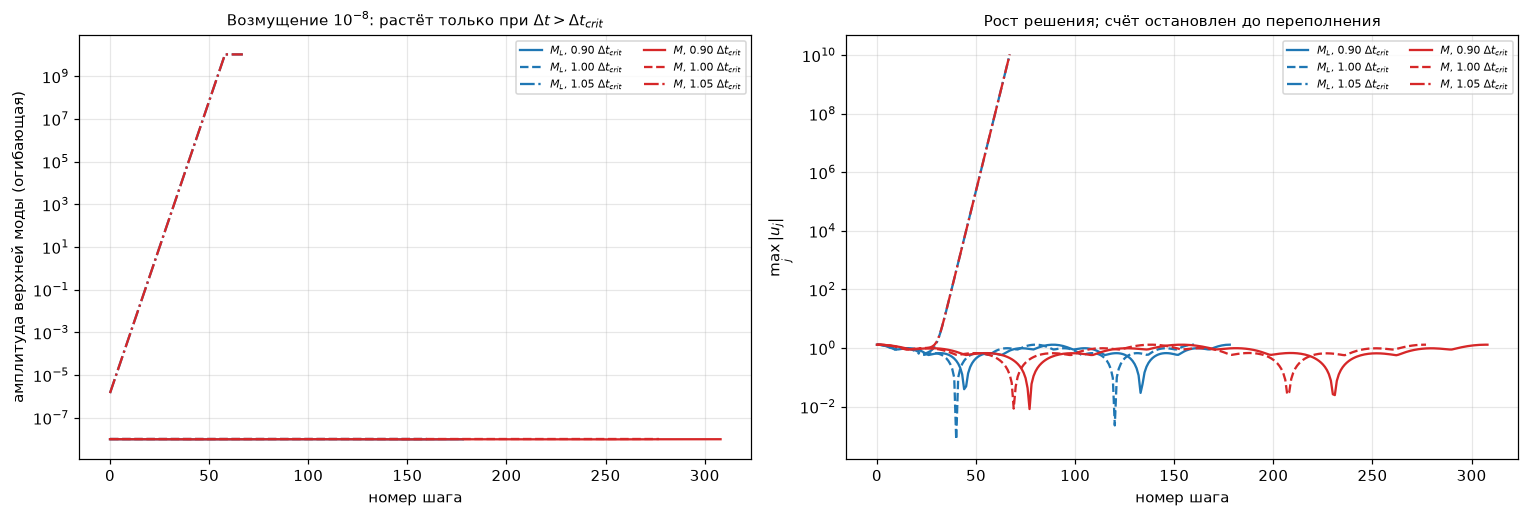

Скорость роста при 1.05 dt_crit:
  lumped     шаг роста |lambda| = 0.6285 за шаг, порядок за 4 шагов
  consistent шаг роста |lambda| = 0.6285 за шаг, порядок за 4 шагов


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8))
colors = {"lumped": "tab:blue", "consistent": "tab:red"}
labels = {"lumped": "$M_L$", "consistent": "$M$"}


def running_max(v, w=9):
    """Огибающая: максимум по окну +-w шагов (мода переворачивается каждый шаг)."""
    return np.array([v[max(0, i - w):i + w + 1].max() for i in range(len(v))])


for (mass, fac), (dt, hist, amp) in results.items():
    n = np.arange(len(hist))
    ls = {0.9: "-", 1.0: "--", 1.05: "-."}[fac]
    axes[0].semilogy(n, np.maximum(running_max(amp), 1e-18), ls, color=colors[mass], lw=1.5,
                     label="%s, %.2f $\\Delta t_{crit}$" % (labels[mass], fac))
    axes[1].semilogy(n, np.abs(hist).max(axis=1), ls, color=colors[mass], lw=1.5,
                     label="%s, %.2f $\\Delta t_{crit}$" % (labels[mass], fac))

axes[0].set_xlabel("номер шага")
axes[0].set_ylabel("амплитуда верхней моды (огибающая)")
axes[0].set_title("Возмущение $10^{-8}$: растёт только при $\\Delta t>\\Delta t_{crit}$")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_xlabel("номер шага")
axes[1].set_ylabel("$\\max_j|u_j|$")
axes[1].set_title("Рост решения; счёт остановлен до переполнения")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

print("Скорость роста при 1.05 dt_crit:")
for mass in ("lumped", "consistent"):
    dt, hist, amp = results[(mass, 1.05)]
    ok = amp > 0
    rate = np.polyfit(np.arange(len(amp))[ok], np.log(amp[ok]), 1)[0]
    per_decade = np.log(10.0) / rate
    print("  %-10s шаг роста |lambda| = %.4f за шаг, порядок за %.0f шагов"
          % (mass, rate, per_decade))

### Проверка двухмодовой модели для обеих масс

Дискретное решение должно совпадать с суммой двух мод, у которых частоты — это частоты задачи
на собственные значения, поправленные на схему Верле: $\tilde\omega_j=\frac{2}{\Delta t}\arcsin\frac{\omega_{h,j}\Delta t}{2}$.

In [17]:
print("Отличие численного решения от двухмодовой модели (N=80, dt=0.5h):")
for mass in ("lumped", "consistent"):
    dt = 0.5 * h_y
    w = spec[mass]["w"]
    wv = 2.0 / dt * np.arcsin(np.clip(w * dt / 2.0, -1.0, 1.0))
    U, V, K, M = verlet(N_y, mass, dt, 2.25)
    t = np.arange(len(U)) * dt
    model = np.array([
        np.sin(np.pi * xe) * np.cos(wv[0] * tt) + 0.3 * np.sin(5 * np.pi * xe) * np.cos(wv[4] * tt)
        for tt in t])
    print("  %-10s max|u - модель| = %.2e ;  фазовый сдвиг моды 5 при t=10: %+.3f рад (%+.1f град)"
          % (mass, np.max(np.abs(U - model)),
             (wv[4] - 5 * np.pi) * 10.0, np.degrees((wv[4] - 5 * np.pi) * 10.0)))

Отличие численного решения от двухмодовой модели (N=80, dt=0.5h):
  lumped     max|u - модель| = 6.60e-13 ;  фазовый сдвиг моды 5 при t=10: -0.189 рад (-10.8 град)
  consistent max|u - модель| = 1.92e-12 ;  фазовый сдвиг моды 5 при t=10: +0.316 рад (+18.1 град)


## Выводы по жёлтому уровню

**Как диагонализация массы меняет собственные частоты.** Меняет знак ошибки, но не её порядок:
$$\frac{\omega_{h,j}}{\omega_j}-1=\mp\frac{(j\pi h)^2}{24}+O(h^4)$$
— у $M_L$ частоты **занижены** (волна отстаёт), у $M$ — на столько же **завышены** (волна спешит).
При $N=80$ для $j=1$: $-6.4\cdot10^{-5}$ и $+6.4\cdot10^{-5}$; для $j=5$: $-1.6\cdot10^{-3}$ и $+1.6\cdot10^{-3}$;
уже при $j=40$ это $\mp10\%$, а у верхней моды ($j=79$) диагональная масса проигрывает заметно:
$-35.5\%$ против $+11.6\%$. Для младших мод модули ошибок совпадают, потому что $K$ и $M$ имеют
общие собственные векторы $z_j=\sin(j\pi x)$; на верхних модах асимптотика $M_L$ работает хуже.

**Допустимый шаг.** Здесь диагональная масса выигрывает: $\omega_{h,\max}=2/h$ у $M_L$ против
$2\sqrt3/h$ у $M$ (множитель $\sqrt3$). Поэтому
$$\Delta t_{crit}^{L}=h,\qquad \Delta t_{crit}^{M}=\frac{h}{\sqrt3}=0.577\,h,$$
то есть с согласованной массой шаг почти вдвое меньше ($0.0125$ против $0.00722$ при $N=80$),
и каждый шаг дороже (нужно решать систему с $M$). Это и есть цена согласованной массы.

**Накопление ошибки фазы.** Энергия здесь схемы не различает: при одном и том же шаге у обеих масс
$\max|H_n-H_0|/H_0\approx1.7\cdot10^{-3}$ и не растёт — а вот фаза ведёт себя по-разному.
Ошибка фазы $\Delta\varphi_j=(\tilde\omega_j-\omega_j)t$ растёт линейно по времени у обеих схем,
но диагональная масса с Верле при $\Delta t\approx0.5\text{–}0.9\,h$ работает лучше, потому что
её пространственное отставание гасится положительной добавкой схемы $(\omega_h\Delta t)^2/24$.
Числа при $N=80$, $t\in[0,10]$:

| вариант | $\Delta t$ | $\max_t E_\infty$ |
|---|---|---|
| $M_L$, $0.5h$ | 0.00625 | $5.7\cdot10^{-2}$ |
| $M_L$, $0.9\Delta t_{crit}$ | 0.01125 | $1.4\cdot10^{-2}$ |
| $M$, $0.5h$ | 0.00625 | $9.4\cdot10^{-2}$ |
| $M$, $0.9\Delta t_{crit}$ | 0.00650 | $9.6\cdot10^{-2}$ |

У $M_L$ фазовая ошибка почти компенсируется: при $\Delta t=0.9h$ от каждой из двух составляющих
остаётся всего $\approx0.2$, у $M$ — они складываются. Поэтому при одинаковом запасе устойчивости
диагональная масса даёт ошибку в 6–7 раз меньше. Уменьшение $\Delta t$ вдвое при той же сетке ошибку
**не** уменьшает ($9.0\cdot10^{-3}\to1.1\cdot10^{-2}$ при $t=2.25$ для $M_L$): она определяется
пространственной дисперсией, а временная часть при большом шаге как раз частично её компенсировала.

**Предельный шаг.** При $\Delta t=0.9\Delta t_{crit}$ возмущение $10^{-8}$ не растёт
(остаётся $\sim10^{-8}$); при $1.00\Delta t_{crit}$ — маргинальный режим, амплитуда не меняется
(любая неточность в $\omega_{\max}$ или округление выводят из него); при $1.05\Delta t_{crit}$ —
экспоненциальный рост с множителем $\approx1.88$ за шаг (порядок за 4 шага): за 67 шагов
возмущение выросло с $10^{-8}$ до $10^{10}$, счёт остановлен до переполнения. Именно поэтому
рабочим режимом $\Delta t=\Delta t_{crit}$ быть не может — нужен запас.